# 01 · Data and descriptors of the validation catalogs

**Question.** Which events does each validation catalog contain (VOISS-Net, VCSEIS, Deception Island, Nevado del Ruiz volcano), by system and by class, and how are the most transferable descriptors (FI, DET, SR) distributed within each system?

Everything is shown **by system**: no distribution mixes volcanoes. Only valid events (`motivo == ""`) that are not duplicates are used. Deception Island is split into its two campaigns (1995 and 2009).

Reads only `../datos/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = "png"
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "font.size": 9})
pd.set_option("display.width", 160, "display.max_columns", 30)
DATOS, RES = Path("../datos"), Path("../resultados")

# English display names for the systems (the data files keep the Spanish names)
SYSTEM_EN = {"Hawái": "Hawai`i", "Norte de California": "Northern California",
             "Nevados de Chillan": "Nevados de Chillán", "Decepcion": "Deception Island",
             "Decepcion95": "Deception Island 1995", "Decepcion09": "Deception Island 2009",
             "Popocatepetl": "Popocatépetl"}

def en(df, cols=("sistema", "fuente", "destino")):
    """Replace system names by their English display names in the given columns."""
    df = df.copy()
    for c in cols:
        if c in df:
            df[c] = df[c].replace(SYSTEM_EN)
    return df

F16 = ["DET", "L", "Lmax", "DIV", "Lentr", "LAM", "TT", "Vmax", "Ventr", "W",
       "Wmax", "Wdiv", "Wentr", "fpeak", "SR", "FI"]

def cargar(ventana):
    """Valid events (empty motivo, no duplicates); Deception Island split by campaign."""
    d = pd.read_parquet(DATOS / f"features16_{ventana}.parquet")
    d = d[(d.motivo == "") & ~d.duplicado.fillna(False).astype(bool)].copy()
    dec = d.sistema == "Decepcion"
    d.loc[dec, "sistema"] = "Decepcion" + d.loc[dec, "item_id"].str.extract(r"dec\.(\d\d)")[0]
    return en(d)

fija, coda = cargar("fija"), cargar("coda")
len(fija), len(coda)

(9325, 9132)

## Inventory by catalog, system and class (fixed window)

In [2]:
inv = pd.crosstab([fija.dataset, fija.sistema], fija.clase, margins=True, margins_name="total")
inv

clase                            AV   EX   HB    LP   OT   RE  TR    VT  total
dataset   sistema                                                             
decepcion Deception Island 1995   0    0    0    48    0    0   0    29     77
          Deception Island 2009   0    0    0   175    0    0   0    24    199
sgc       Ruiz-Bis                0    0   70   173    0    0   0     5    248
          Ruiz-Olleta             0    0  389   176    0    0   0   216    781
vcseis    Alaska                  1    0    0   459  357  163   2   416   1398
          Cascade                 0    0    0   170    0    0   0   186    356
          Hawai`i                 0    0    0   398    0    0   0   352    750
          Northern California     0    0    0   327    0    0   0   361    688
voissnet  Kilauea                 0    0    0     0    0    0   0   878    878
          Pavlof                  0  145    0    61    0    0   0     0    206
          Redoubt                 0    0    0     0    0    0   0   961    961
          Semisopochnoi           0  299    0   715    0    0   0     0   1014
          Tanaga                  0    0    0     0    0    0   0   936    936
          Veniaminof              0    0    0   833    0    0   0     0    833
total                             1  444  459  3535  357  163   2  4364   9325

Continuous signals (tremor, noise), used only as a reference for classes other than LP/VT:

In [3]:
cont = en(pd.read_parquet(DATOS / "features16_continuas.parquet"))
cont = cont[cont.motivo == ""]
pd.crosstab([cont.dataset, cont.sistema], cont.clase)

clase                            NTR  RUIDO    TR
dataset   sistema                                
decepcion Deception Island 1995   87      0     0
          Deception Island 2009  435      0     0
sgc       Ruiz-Bis                 0      0   250
          Ruiz-Olleta              0      0   250
voissnet  Pavlof                   0    500  1436
          Popocatépetl             0      0   500
          Semisopochnoi            0    500   717
          Veniaminof               0      0   422

## Distribution of FI, DET and SR by system and class

Each box is one system and one class; classes with fewer than 20 events in a system are not drawn.

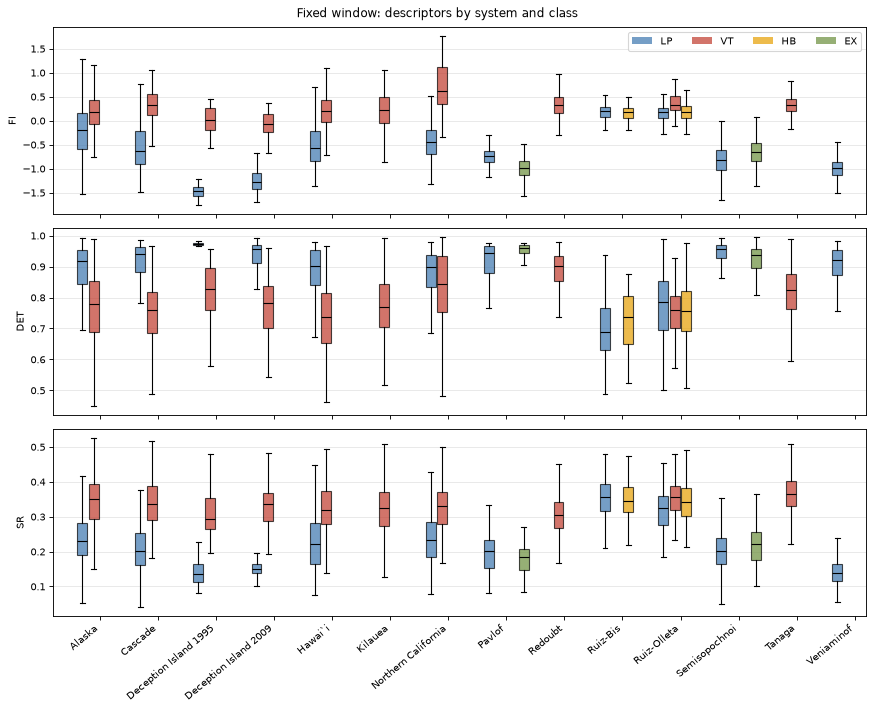

In [4]:
CLASES = ["LP", "VT", "HB", "EX"]
COLOR = {"LP": "#3b75af", "VT": "#c0392b", "HB": "#e69f00", "EX": "#6a8e3b"}
sistemas = sorted(fija.sistema.unique())
fig, ejes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, desc in zip(ejes, ["FI", "DET", "SR"]):
    for i, s in enumerate(sistemas):
        for j, c in enumerate(CLASES):
            v = fija.loc[(fija.sistema == s) & (fija.clase == c), desc].dropna()
            if len(v) < 20:
                continue
            b = ax.boxplot(v, positions=[i + (j - 1.5) * 0.2], widths=0.17, showfliers=False,
                           patch_artist=True)
            b["boxes"][0].set(facecolor=COLOR[c], alpha=.7)
            b["medians"][0].set(color="k")
    ax.set_ylabel(desc)
    ax.grid(axis="y", alpha=.3)
ejes[-1].set_xticks(range(len(sistemas)))
ejes[-1].set_xticklabels(sistemas, rotation=40, ha="right")
ejes[0].legend([plt.Rectangle((0, 0), 1, 1, fc=COLOR[c], alpha=.7) for c in CLASES], CLASES,
               ncol=4, loc="upper right")
fig.suptitle("Fixed window: descriptors by system and class")
fig.tight_layout()

Medians by system and class (LP and VT), to read the numbers in the figure:

In [5]:
(fija[fija.clase.isin(["LP", "VT"])]
 .groupby(["sistema", "clase"])[["FI", "DET", "SR"]].median().round(3)
 .unstack("clase"))

FI           DET            SR       
clase                     LP     VT     LP     VT     LP     VT
sistema                                                        
Alaska                -0.194  0.182  0.917  0.781  0.231  0.350
Cascade               -0.625  0.319  0.941  0.760  0.202  0.336
Deception Island 1995 -1.464  0.017  0.972  0.829  0.137  0.293
Deception Island 2009 -1.284 -0.071  0.957  0.784  0.149  0.336
Hawai`i               -0.580  0.199  0.903  0.737  0.221  0.318
Kilauea                  NaN  0.229    NaN  0.769    NaN  0.325
Northern California   -0.451  0.625  0.899  0.845  0.234  0.331
Pavlof                -0.745    NaN  0.945    NaN  0.202    NaN
Redoubt                  NaN  0.334    NaN  0.902    NaN  0.305
Ruiz-Bis               0.192  0.302  0.687  0.722  0.356  0.354
Ruiz-Olleta            0.186  0.335  0.786  0.759  0.325  0.357
Semisopochnoi         -0.819    NaN  0.958    NaN  0.200    NaN
Tanaga                   NaN  0.322    NaN  0.823    NaN  0.365
Veniaminof            -0.982    NaN  0.923    NaN  0.139    NaN

## Relation between windows (fixed versus up to the end of the coda)

For the same events, Spearman correlation between the value of the descriptor in the fixed window and in the window up to the end of the coda, by system.

In [6]:
par = fija.merge(coda, on="item_id", suffixes=("_fija", "_coda"))
par = par[par.sistema_fija == par.sistema_coda]
rho = (par.groupby("sistema_fija")
       .apply(lambda g: pd.Series({d: g[f"{d}_fija"].corr(g[f"{d}_coda"], method="spearman")
                                   for d in ["FI", "DET", "SR"]} | {"n": len(g)}))
       .rename_axis("sistema"))
rho.round(3)

,FI,DET,SR,n
sistema,,,,
Alaska,0.954,0.628,0.855,1380.0
Cascade,0.983,0.672,0.892,347.0
Deception Island 1995,0.972,0.789,0.977,57.0
Deception Island 2009,0.960,0.943,0.935,194.0
Hawai`i,0.983,0.720,0.853,749.0
Kilauea,0.974,0.454,0.724,878.0
Northern California,0.996,0.615,0.918,688.0
Pavlof,0.693,0.398,0.306,206.0
Redoubt,0.983,0.691,0.876,961.0


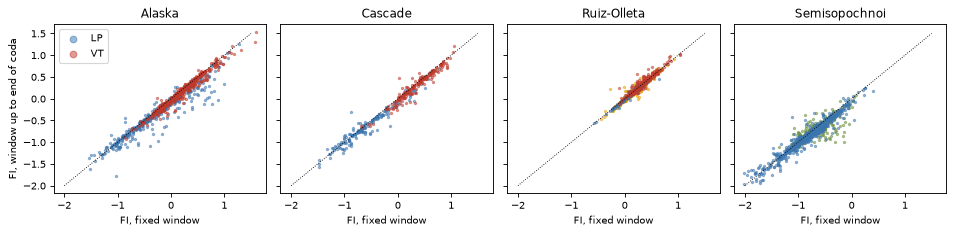

In [7]:
muestra = ["Alaska", "Cascade", "Ruiz-Olleta", "Semisopochnoi"]
fig, ejes = plt.subplots(1, len(muestra), figsize=(12, 3), sharex=True, sharey=True)
for ax, s in zip(ejes, muestra):
    g = par[(par.sistema_fija == s) & par.clase_fija.isin(["LP", "VT", "HB", "EX"])]
    for c, h in g.groupby("clase_fija"):
        ax.scatter(h.FI_fija, h.FI_coda, s=4, alpha=.5, color=COLOR[c], label=c)
    ax.plot([-2, 1.5], [-2, 1.5], "k:", lw=.8)
    ax.set_title(s); ax.set_xlabel("FI, fixed window")
ejes[0].set_ylabel("FI, window up to end of coda"); ejes[0].legend(markerscale=3)
fig.tight_layout()